# Notebook 5 - Route 3: clean, train, and explain

**Question:** can historical information improve Route 3 arrival predictions over the published timetable?

Route 3 runs between Downtown Station and N Main Post Office. We apply the Route 7 research procedure, but fit new coefficients, feature choices, and historical summaries.

## Before running
Put `RTS_Route3_Spring2023.xlsx` and `RTS_GTFS_Spring2023.zip` in the **same folder** as this notebook. Select the Python kernel and run top to bottom. Executed results and a plot are included. No previous notebook or prepared CSV is required. Original files are never overwritten.

| Section | Purpose |
|---|---|
| 1 | Load libraries, show the dataframe, and follow one bus |
| 2 | Clean fields and flag questionable records |
| 3 | Read the applicable historical schedule |
| 4 | Match scheduled visits and check journey evidence |
| 5 | Keep intermediate arrival labels and fixed date splits |
| 6 | Explain regression statistics and backward selection |
| 7 | Compare schedule, median, regression, ridge, and forest |
| 8 | Interpret results and answer research questions |

**Delay = actual arrival minus scheduled arrival**, in minutes. Positive means late. **Predicted arrival = scheduled arrival + predicted delay.**

We model only explicitly timed intermediate stops. We do not invent times for untimed stops or treat terminal arrival as departure. Schedule assignments remain provisional.

**No look-ahead predictors:** only direction, scheduled hour, and weekday are used. Bus ID, actual arrival, passenger counts recorded at the target stop, audit fields, and outlier flags are excluded. Retrospective journey checks support labels; they do not establish a live matcher. Every fold fits preprocessing, feature selection, and ridge tuning on earlier dates only. Final-test outcomes remain unscored.

## 1. Load libraries and inspect the dataframe

Each row is a stop visit, not a complete trip. Stop ID is a location; stop sequence is its position within a direction. One bus repeats the route throughout the day.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import zipfile
from itertools import combinations
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

raw = pd.read_excel("RTS_Route3_Spring2023.xlsx", engine="openpyxl")
display(raw.head())
print("Stop visits:", len(raw), "Buses:", raw.Bus.nunique(), "Dates:", raw.Date.nunique())
display(raw.isna().sum().to_frame("missing_values"))

Stop visits: 8642 Buses: 3 Dates: 17


,Route,Stop ID,Stop Name,Stop Seq ID,Day of Week,Date,Arrive,Passenger On,Passenger Off,Passenger Load,Passenger Miles,Interstop Distance,Bus,Lat.,Long.
0,3-Downtown Station To N Main Post Office,1,Rosa Parks RTS Downtown Station,0,Wednesday,2023-03-01,09:33:31,1,0,1,0.000,0.00,2103,29.64554,-82.32234
1,3-Downtown Station To N Main Post Office,60,SE 4TH STREET SE 10TH AVENUE,1,Wednesday,2023-03-01,09:34:14,0,0,1,0.354,0.35,2103,29.64113,-82.31966
2,3-Downtown Station To N Main Post Office,61,DIGNITY PROJECT,2,Wednesday,2023-03-01,09:34:30,0,0,1,0.196,0.20,2103,29.63861,-82.31839
3,3-Downtown Station To N Main Post Office,63,NORWOOD NEIGHBORHOOD,3,Wednesday,2023-03-01,09:34:51,0,0,1,0.212,0.21,2103,29.63586,-82.31706
4,3-Downtown Station To N Main Post Office,64,Sugarhill Neighborhood @ SE 4th Street,4,Wednesday,2023-03-01,09:35:10,0,0,1,0.183,0.18,2103,29.63353,-82.31582


,missing_values
Route,0
Stop ID,0
Stop Name,0
Stop Seq ID,0
Day of Week,0
Date,0
Arrive,0
Passenger On,0
Passenger Off,0
Passenger Load,0


### Read the features

| Columns | Meaning and role |
|---|---|
| Date, Arrive | Recorded arrival timestamp: used to calculate the target |
| Bus | Vehicle ID: trace records and inspect errors |
| Stop ID, Stop Name | Location labels; numeric IDs do not imply order |
| Stop Seq ID | Ordered position within a direction; resets between journeys |
| Passenger On/Off/Load | Activity recorded at the stop; unavailable before that arrival |
| Lat., Long. | Recorded location; possible support for later quality checks |
| Passenger Miles, Interstop Distance | Operational measures, unused in this first model |

Do not pass every numeric column to the model. Information recorded during the arrival being predicted can reveal the answer.

## 2. Clean a working copy and inspect a bus-day

Preserve `source_row` to trace an observation back to Excel (Excel row = source_row + 2). Remove only exact full-row copies. Standardize identifiers and timestamps, then flag invalid IDs/sequences, repeated keys, and tied times. Flags require review; they do not prove an observation is wrong.

In [2]:
data = raw.copy()
data["source_row"] = data.index
data = data.drop_duplicates(subset=raw.columns.tolist()).copy()
data["bus_id"] = data["Bus"].astype("string")
data["stop_id"] = data["Stop ID"].astype("string").str.replace(r"\.0$", "", regex=True)
data["stop_sequence"] = pd.to_numeric(data["Stop Seq ID"], errors="coerce")
data["service_date"] = pd.to_datetime(data["Date"], errors="coerce").dt.normalize()
clock = pd.to_timedelta(data["Arrive"].astype(str), errors="coerce")
clock = clock.where((clock >= pd.Timedelta(0)) & (clock < pd.Timedelta(days=1)))
data["actual_arrival"] = data["service_date"] + clock

print("Rows before:", len(raw), "After exact-copy rule:", len(data))
display(data[["source_row", "bus_id", "stop_id", "stop_sequence", "actual_arrival"]].head())
bad_fields = (
    data[["bus_id", "stop_id", "stop_sequence", "actual_arrival"]].isna().any(axis=1)
    | (data["stop_sequence"] < 0) | (data["stop_sequence"] % 1 != 0)
    | (data["stop_sequence"] == 999) | data["stop_id"].eq("9999").fillna(True)
)
repeated_key = data.duplicated(["bus_id", "service_date", "stop_id", "actual_arrival"], keep=False)
tied_time = data.duplicated(["bus_id", "service_date", "actual_arrival"], keep=False)
data["needs_review"] = bad_fields | repeated_key | tied_time

display(pd.Series({"invalid_fields": int(bad_fields.sum()),
                   "repeated_key_rows": int(repeated_key.sum()),
                   "tied_time_rows": int(tied_time.sum())}).to_frame("flagged_rows"))
display(data.loc[data["needs_review"], ["source_row", "bus_id", "stop_id", "actual_arrival"]].head(6))

Rows before: 8642 After exact-copy rule: 8642


,source_row,bus_id,stop_id,stop_sequence,actual_arrival
0,0,2103,1,0,2023-03-01 09:33:31
1,1,2103,60,1,2023-03-01 09:34:14
2,2,2103,61,2,2023-03-01 09:34:30
3,3,2103,63,3,2023-03-01 09:34:51
4,4,2103,64,4,2023-03-01 09:35:10


,flagged_rows
invalid_fields,138
repeated_key_rows,486
tied_time_rows,493


,source_row,bus_id,stop_id,actual_arrival
32,32,2103,1468,2023-03-01 09:55:38
33,33,2103,1468,2023-03-01 09:55:38
64,64,2103,1,2023-03-01 10:24:11
65,65,2103,1,2023-03-01 10:24:11
97,97,2103,1468,2023-03-01 10:57:03
98,98,2103,1468,2023-03-01 10:57:03


In [3]:
bus_summary = data.groupby(["bus_id", "service_date"]).agg(visits=("source_row", "size"), first_arrival=("actual_arrival", "min"), last_arrival=("actual_arrival", "max")).reset_index()
display(bus_summary.head(10))
bus, day = data.bus_id.iloc[0], data.service_date.iloc[0]
one_bus_day = data.loc[data.bus_id.eq(bus) & data.service_date.eq(day)]
display(one_bus_day[["source_row", "bus_id", "Stop Name", "stop_sequence", "actual_arrival", "needs_review"]].head(15))
all_dates = sorted(data.service_date.dropna().unique())
train_dates, validation_dates, reserved_dates = all_dates[:10], all_dates[10:13], all_dates[13:]
for label, dates in [("Train", train_dates), ("Validation", validation_dates), ("Reserved final test", reserved_dates)]:
    print(label, [str(pd.Timestamp(d).date()) for d in dates])

Train ['2023-03-01', '2023-03-02', '2023-03-03', '2023-03-06', '2023-03-07', '2023-03-08', '2023-03-09', '2023-03-10', '2023-03-13', '2023-03-14']
Validation ['2023-03-15', '2023-03-16', '2023-03-17']
Reserved final test ['2023-03-20', '2023-03-21', '2023-03-22', '2023-03-23']


,bus_id,service_date,visits,first_arrival,last_arrival
0,1604,2023-03-17,325,2023-03-17 12:02:33,2023-03-17 17:23:58
1,1605,2023-03-15,520,2023-03-15 09:30:49,2023-03-15 17:28:12
2,2103,2023-03-01,520,2023-03-01 09:33:31,2023-03-01 17:27:04
3,2103,2023-03-02,531,2023-03-02 09:28:55,2023-03-02 17:40:58
4,2103,2023-03-03,520,2023-03-03 09:33:00,2023-03-03 17:27:29
5,2103,2023-03-06,519,2023-03-06 09:36:25,2023-03-06 17:30:43
6,2103,2023-03-07,518,2023-03-07 09:32:05,2023-03-07 17:30:14
7,2103,2023-03-08,520,2023-03-08 09:31:44,2023-03-08 17:27:07
8,2103,2023-03-09,534,2023-03-09 09:30:51,2023-03-09 17:30:55
9,2103,2023-03-10,520,2023-03-10 09:31:05,2023-03-10 17:25:12


,source_row,bus_id,Stop Name,stop_sequence,actual_arrival,needs_review
0,0,2103,Rosa Parks RTS Downtown Station,0,2023-03-01 09:33:31,False
1,1,2103,SE 4TH STREET SE 10TH AVENUE,1,2023-03-01 09:34:14,False
2,2,2103,DIGNITY PROJECT,2,2023-03-01 09:34:30,False
3,3,2103,NORWOOD NEIGHBORHOOD,3,2023-03-01 09:34:51,False
4,4,2103,Sugarhill Neighborhood @ SE 4th Street,4,2023-03-01 09:35:10,False
5,5,2103,Eastbound SE 22nd Avenue @ SE 12th Street,5,2023-03-01 09:36:00,False
6,6,2103,Eastbound SE 22nd Avenue @ SE 13th Street,6,2023-03-01 09:36:10,False
7,7,2103,McPherson Recreational Center,7,2023-03-01 09:36:51,False
8,8,2103,Northbound SE 15th Street @ SE 13th Place,8,2023-03-01 09:37:16,False
9,9,2103,Lincoln Estate Neighborhood,9,2023-03-01 09:37:20,False


## 3. Read the historical timetable and service calendar

GTFS contains trips, stop patterns, and published times. The calendar and exceptions identify active trips on each date. Blank arrival-time fields are not published intermediate times and are excluded. Inspect Route 3's own timed stops instead of carrying over Route 7's stop IDs or sequence numbers.

In [4]:
def read_schedule_table(filename):
    with zipfile.ZipFile("RTS_GTFS_Spring2023.zip") as archive:
        table = pd.read_csv(archive.open(filename), dtype=str, keep_default_na=False)
    table.columns = table.columns.str.strip()
    return table.apply(lambda column: column.str.strip())

trips = read_schedule_table("trips.txt")
stop_times = read_schedule_table("stop_times.txt")
calendar = read_schedule_table("calendar.txt")
exceptions = read_schedule_table("calendar_dates.txt")
stops = read_schedule_table("stops.txt")

route3_trips = trips.loc[trips["route_id"] == "3"]
display(route3_trips[["trip_id", "direction_id", "service_id", "trip_headsign"]].head())
route3_times = route3_trips.merge(stop_times, on="trip_id", validate="one_to_many")
route3_times = route3_times.loc[route3_times["arrival_time"] != ""].copy()
route3_times = route3_times.merge(stops[["stop_id", "stop_name"]], on="stop_id", validate="many_to_one")

scheduled_days = []
for date in sorted(data["service_date"].dropna().unique()):
    date = pd.Timestamp(date)
    date_code = date.strftime("%Y%m%d")
    active = set(calendar.loc[
        (calendar["start_date"] <= date_code) & (calendar["end_date"] >= date_code)
        & (calendar[date.day_name().lower()] == "1"), "service_id"
    ])
    for change in exceptions.loc[exceptions["date"] == date_code].itertuples(index=False):
        if change.exception_type == "1":
            active.add(change.service_id)
        elif change.exception_type == "2":
            active.discard(change.service_id)
    day_schedule = route3_times.loc[route3_times["service_id"].isin(active)].copy()
    day_schedule["service_date"] = date
    day_schedule["scheduled_arrival"] = date + pd.to_timedelta(day_schedule["arrival_time"])
    scheduled_days.append(day_schedule)

schedule = pd.concat(scheduled_days, ignore_index=True)
schedule["stop_sequence"] = pd.to_numeric(schedule["stop_sequence"])
display(schedule[["service_date", "trip_id", "direction_id", "stop_id", "scheduled_arrival"]].head())

,trip_id,direction_id,service_id,trip_headsign
477,5003001,0,SWB,To N Main Post Office
478,5003003,0,SWB,To N Main Post Office
479,5003005,0,SWB,To N Main Post Office
480,5003007,0,SWB,To N Main Post Office
481,5003009,0,SWB,To N Main Post Office


,service_date,trip_id,direction_id,stop_id,scheduled_arrival
0,2023-03-01,1003001,0,1,2023-03-01 09:30:00
1,2023-03-01,1003001,0,1235,2023-03-01 09:47:00
2,2023-03-01,1003001,0,1468,2023-03-01 09:55:00
3,2023-03-01,1003003,0,1,2023-03-01 10:30:00
4,2023-03-01,1003003,0,1235,2023-03-01 10:47:00


In [5]:
trip_patterns = route3_trips.merge(stop_times, on="trip_id")
trip_patterns["seq"] = pd.to_numeric(trip_patterns.stop_sequence)
full_patterns = {tid: list(zip(g.sort_values("seq")["seq"], g.sort_values("seq").stop_id)) for tid, g in trip_patterns.groupby("trip_id")}
trip_last_sequence = {tid: max(seq for seq, stop in pattern) for tid, pattern in full_patterns.items()}
display(schedule[["direction_id", "stop_sequence", "stop_id", "stop_name"]].drop_duplicates().sort_values(["direction_id", "stop_sequence"]))
dev = data.loc[data.service_date.isin(train_dates + validation_dates)].sort_values(["bus_id", "service_date", "source_row"]).copy()
planned = schedule.loc[schedule.service_date.isin(train_dates + validation_dates)].copy()

,direction_id,stop_sequence,stop_id,stop_name
0,0,0,1,Rosa Parks RTS Downtown Station
1,0,24,1235,NE Walmart Supercenter
2,0,32,1468,N Main Post Office
24,1,0,1468,N Main Post Office
25,1,7,1234,NE Walmart Supercenter
26,1,30,1,Rosa Parks RTS Downtown Station


## 4. Propose schedule links, then check surrounding journeys

Join on date + stop ID + sequence position. Keep a unique scheduled candidate within 20 minutes, then remove competing claims on one scheduled visit. This **infers** a scheduled trip; the raw workbook has no direct trip ID.

The matching window can exclude extreme delays and create ambiguity when service is frequent. Scores therefore describe the retained population. A training-only window-coverage table is shown below; we do not pick a window based on validation errors.

The journey audit checks stop-pattern consistency, increasing source timestamps, and a unique scheduled trip supported by **other timepoints**, leaving the target arrival out of that corroboration. Terminal timestamps may support a historical assignment while still being unsuitable departure-delay labels. These checks improve evidence but do not independently verify ground truth.

In [6]:
observations = dev.loc[~dev.needs_review].copy()
candidates = observations.merge(planned, on=["service_date", "stop_id", "stop_sequence"], how="inner")
candidates["matching_gap_minutes"] = (candidates.actual_arrival - candidates.scheduled_arrival).dt.total_seconds().abs() / 60
MATCH_WINDOW_MINUTES = 20
possible = candidates.loc[candidates.matching_gap_minutes.le(MATCH_WINDOW_MINUTES)].copy()
possible["candidate_count"] = possible.groupby("source_row").source_row.transform("size")
matched = possible.loc[possible.candidate_count.eq(1)].copy()
conflict = matched.duplicated(["service_date", "trip_id", "stop_sequence"], keep=False)
conflict_review = matched.loc[conflict].copy()
matched = matched.loc[~conflict].copy()
print("Proposed unique development matches:", len(matched), "Conflicting claims held:", len(conflict_review))
display(matched[["source_row", "bus_id", "service_date", "stop_id", "direction_id", "scheduled_arrival", "actual_arrival"]].head(8))
coverage = []
for minutes in [10, 15, 20, 25, 30]:
    trial = candidates.loc[candidates.service_date.isin(train_dates) & candidates.matching_gap_minutes.le(minutes)]
    counts = trial.groupby("source_row").size()
    coverage.append({"window_minutes": minutes, "unique_candidates_before_conflict_check": int(counts.eq(1).sum()), "ambiguous_records": int(counts.gt(1).sum())})
display(pd.DataFrame(coverage))

Proposed unique development matches: 306 Conflicting claims held: 0


,source_row,bus_id,service_date,stop_id,direction_id,scheduled_arrival,actual_arrival
11,6267,1604,2023-03-17,1235,0,2023-03-17 12:47:00,2023-03-17 12:57:26
19,6282,1604,2023-03-17,1234,1,2023-03-17 13:08:00,2023-03-17 13:09:54
28,6330,1604,2023-03-17,1235,0,2023-03-17 13:47:00,2023-03-17 13:52:26
36,6341,1604,2023-03-17,1468,1,2023-03-17 14:00:00,2023-03-17 14:01:24
44,6347,1604,2023-03-17,1234,1,2023-03-17 14:08:00,2023-03-17 14:05:53
53,6395,1604,2023-03-17,1235,0,2023-03-17 14:47:00,2023-03-17 14:56:48
61,6406,1604,2023-03-17,1468,1,2023-03-17 15:00:00,2023-03-17 15:13:17
69,6412,1604,2023-03-17,1234,1,2023-03-17 15:08:00,2023-03-17 15:19:38


,window_minutes,unique_candidates_before_conflict_check,ambiguous_records
0,10,245,0
1,15,246,0
2,20,247,0
3,25,247,0
4,30,247,0


### Journey audit support

The following helper functions repeat the journey-evidence checks introduced for Route 7, with Route 3's own stop patterns and endpoints. Focus on the output counts first; inspect the helper code when reviewing a particular match. Source-order blocks are inferred at sequence resets and are not official trip IDs.

In [7]:
# Audit development dates only. Do not use final-test outcomes to change rules.
development_dates=sorted(data.service_date.dropna().unique())[:13]
dev=data[data.service_date.isin(development_dates)].sort_values(['bus_id','service_date','source_row']).copy()
planned=schedule[schedule.service_date.isin(development_dates)].copy()
matched=matched[matched.service_date.isin(development_dates)].copy()
g=dev.groupby(['bus_id','service_date'],sort=False)
dev['new_source_block']=g.cumcount().eq(0)|dev.stop_sequence.lt(g.stop_sequence.shift())
dev['block_number']=dev.groupby(['bus_id','service_date'])['new_source_block'].cumsum()
dev['block_id']=dev.bus_id.astype(str)+'|'+dev.service_date.dt.strftime('%Y-%m-%d')+'|'+dev.block_number.astype(str)
blocks=dict(tuple(dev.groupby('block_id',sort=False)))
block_by_source=dev.set_index('source_row').block_id
trip_patterns=route3_trips.merge(stop_times,on='trip_id')
trip_patterns['seq']=pd.to_numeric(trip_patterns.stop_sequence)
full_patterns={tid:list(zip(t.sort_values('seq')['seq'],t.sort_values('seq').stop_id)) for tid,t in trip_patterns.groupby('trip_id')}
date_trips={d:t for d,t in planned.groupby('service_date')}


def timepoint_anchors(block,target_sequence):
    """Other unique recorded timepoint positions, retaining ambiguity flags."""
    keys=planned[['stop_id','stop_sequence']].drop_duplicates()
    anchors=block.merge(keys,on=['stop_id','stop_sequence'],how='inner')
    anchors=anchors[anchors.stop_sequence.ne(target_sequence)&anchors.actual_arrival.notna()].copy()
    valid=anchors.groupby('stop_sequence').actual_arrival.transform('nunique').eq(1)
    return anchors[valid].drop_duplicates(['stop_sequence','stop_id','actual_arrival'])

def external_candidate_ids(anchors,observed_pattern,day):
    """Leave target arrival entirely out of the assignment check."""
    if anchors.empty or len(observed_pattern)<5:return []
    candidate_ids=[]
    for tid,t in date_trips[day].groupby('trip_id'):
        expected=dict(full_patterns[tid])
        if any(expected.get(seq)!=stop for seq,stop in observed_pattern):continue
        joined=anchors.merge(t[['stop_id','stop_sequence','scheduled_arrival']],on=['stop_id','stop_sequence'])
        if joined.stop_sequence.nunique()!=anchors.stop_sequence.nunique():continue
        offset=(joined.actual_arrival-joined.scheduled_arrival).dt.total_seconds()/60
        if offset.abs().le(20).all():candidate_ids.append(tid)
    return candidate_ids



In [8]:
audit_rows=[]
for visit in matched.itertuples():
    block=blocks[block_by_source.loc[visit.source_row]]
    ordinary=block[block.stop_sequence.between(0, max(trip_last_sequence.values()))&block.stop_id.ne('9999')]
    observed=list(dict.fromkeys(zip(ordinary.stop_sequence,ordinary.stop_id)))
    expected=full_patterns[visit.trip_id]
    expected_map=dict(expected)
    other_pattern=[(seq,stop) for seq,stop in observed if seq!=visit.stop_sequence]
    all_anchors=timepoint_anchors(block,visit.stop_sequence)
    strict=all_anchors[~all_anchors.needs_review]
    weak_ids=external_candidate_ids(all_anchors,other_pattern,visit.service_date)
    strict_ids=external_candidate_ids(strict,other_pattern,visit.service_date)
    if not all_anchors.empty and len(other_pattern)>=5:
        if len(weak_ids)==1:
            status='same_trip_supported_by_other_anchors' if weak_ids[0]==visit.trip_id else 'different_trip_suggested'
        elif len(weak_ids)>1:status='ambiguous_other_anchors'
        else:status='other_anchors_do_not_support_current_trip'
    else:status='insufficient_external_anchor_or_pattern_evidence'
    audit_rows.append({'source_row':visit.source_row,'date':str(visit.service_date.date()),'bus_id':visit.bus_id,
        'stop_id':visit.stop_id,'stop_sequence':visit.stop_sequence,'direction_id':visit.direction_id,
        'current_trip_id':visit.trip_id,'block_id':block_by_source.loc[visit.source_row],
        'full_ordered_pattern_matches':observed==expected,
        'pattern_mismatches':sum(expected_map.get(seq)!=stop for seq,stop in observed),
        'source_times_monotonic':block.actual_arrival.is_monotonic_increasing,
        'other_unique_timed_anchors':len(all_anchors),'other_unflagged_timed_anchors':len(strict),
        'external_candidate_count':len(weak_ids),'external_candidate_trip_ids':';'.join(weak_ids),
        'strict_external_candidate_count':len(strict_ids),
        'strict_same_trip_supported':len(strict_ids)==1 and strict_ids[0]==visit.trip_id,
        'external_check_status':status,
        'source_block_rows':','.join(str(int(x)) for x in block.source_row)})
linkage_audit=pd.DataFrame(audit_rows)

display(linkage_audit.external_check_status.value_counts().to_frame("visits"))
display(linkage_audit.pattern_mismatches.value_counts().to_frame("visits"))

,visits
external_check_status,
same_trip_supported_by_other_anchors,306


,visits
pattern_mismatches,
0,306


## 5. Keep intermediate arrival labels and preserve exclusions

Keep supported, monotonic, pattern-consistent arrivals at explicitly timed intermediate stops. Exclude the first/last sequence of each scheduled trip because terminal arrival/departure semantics need separate review.

Route 3's retained intermediate locations are the two directional Walmart stops. Here stop ID and direction represent the same division, so use direction rather than including redundant copies of both.

Flag unusual delays with training-only IQR fences separately by direction. Retain those observations; an unusual delay is not automatically erroneous. Never use these outcome-based flags as predictors.

In [9]:
core = matched.merge(linkage_audit[["source_row", "pattern_mismatches", "source_times_monotonic", "external_check_status", "strict_same_trip_supported"]], on="source_row", validate="one_to_one")
keep = (core.stop_sequence.gt(0) & core.stop_sequence.lt(core.trip_id.map(trip_last_sequence)) & core.pattern_mismatches.eq(0) & core.source_times_monotonic & core.external_check_status.eq("same_trip_supported_by_other_anchors"))
cleaned = core.loc[keep].copy()
cleaned["delay_minutes"] = (cleaned.actual_arrival - cleaned.scheduled_arrival).dt.total_seconds() / 60
cleaned["scheduled_hour"] = cleaned.scheduled_arrival.dt.hour
cleaned["weekday"] = cleaned.service_date.dt.day_name()
cleaned["split"] = np.where(cleaned.service_date.isin(train_dates), "train", "validation")
cleaned["linkage_status"] = np.where(cleaned.strict_same_trip_supported, "provisional: unflagged other-anchor support", "provisional: terminal-dependent support")
keys = planned[["service_date", "stop_id", "stop_sequence"]].drop_duplicates()
timed_records = dev.merge(keys, on=["service_date", "stop_id", "stop_sequence"], validate="many_to_one")
held = timed_records.loc[~timed_records.source_row.isin(cleaned.source_row)].copy()
held["hold_reason"] = "flagged, ambiguous, unmatched, or unsupported: review required"
terminal_pairs = {(seq, stop) for pattern in full_patterns.values() for seq, stop in [pattern[0], pattern[-1]]}
terminal = pd.Series([(seq, stop) in terminal_pairs for seq, stop in zip(held.stop_sequence, held.stop_id)], index=held.index)
held.loc[terminal, "hold_reason"] = "terminal arrival/departure semantics: excluded from this analysis"
train = cleaned.loc[cleaned.split.eq("train")].copy()
validation = cleaned.loc[cleaned.split.eq("validation")].copy()
assert train.service_date.max() < validation.service_date.min()
assert cleaned.source_row.is_unique
assert not cleaned.duplicated(["service_date", "trip_id", "stop_sequence"]).any()
assert len(cleaned) + len(held) == len(timed_records)
assert cleaned.service_date.max() < min(reserved_dates)
fences = train.groupby("direction_id").delay_minutes.quantile([0.25, 0.75]).unstack()
fences["lower"] = fences[0.25] - 1.5 * (fences[0.75] - fences[0.25])
fences["upper"] = fences[0.75] + 1.5 * (fences[0.75] - fences[0.25])
cleaned["iqr_flag"] = cleaned.delay_minutes.lt(cleaned.direction_id.map(fences.lower)) | cleaned.delay_minutes.gt(cleaned.direction_id.map(fences.upper))
counts = pd.Series({"raw_stop_visits_all_dates": len(raw), "development_raw_visits": len(dev), "development_timepoint_records": len(timed_records), "proposed_matches": len(matched), "cleaned_intermediate_arrivals": len(cleaned), "held_timepoint_records": len(held), "training_labels": len(train), "validation_labels": len(validation), "unusual_delays_retained": int(cleaned.iqr_flag.sum())})
display(counts.to_frame("records"))
display(cleaned.groupby(["split", "direction_id", "stop_id"]).delay_minutes.agg(["size", "median", "min", "max"]))
display(held.hold_reason.value_counts().to_frame("held_records"))
display(cleaned.linkage_status.value_counts().to_frame("records"))
display(cleaned[["source_row", "service_date", "bus_id", "stop_id", "scheduled_arrival", "actual_arrival", "delay_minutes"]].head(8))

,records
raw_stop_visits_all_dates,8642
development_raw_visits,6562
development_timepoint_records,673
proposed_matches,306
cleaned_intermediate_arrivals,196
held_timepoint_records,477
training_labels,155
validation_labels,41
unusual_delays_retained,12


size    median       min        max
split      direction_id stop_id                                     
train      0            1235       79  1.483333 -2.716667  10.166667
           1            1234       76  0.041667 -6.250000   8.916667
validation 0            1235       21  4.783333  1.400000  10.433333
           1            1234       20 -0.258333 -3.783333  11.633333

,held_records
hold_reason,
terminal arrival/departure semantics: excluded from this analysis,477


,records
linkage_status,
provisional: unflagged other-anchor support,100
provisional: terminal-dependent support,96


,source_row,service_date,bus_id,stop_id,scheduled_arrival,actual_arrival,delay_minutes
0,6267,2023-03-17,1604,1235,2023-03-17 12:47:00,2023-03-17 12:57:26,10.433333
1,6282,2023-03-17,1604,1234,2023-03-17 13:08:00,2023-03-17 13:09:54,1.900000
2,6330,2023-03-17,1604,1235,2023-03-17 13:47:00,2023-03-17 13:52:26,5.433333
4,6347,2023-03-17,1604,1234,2023-03-17 14:08:00,2023-03-17 14:05:53,-2.116667
5,6395,2023-03-17,1604,1235,2023-03-17 14:47:00,2023-03-17 14:56:48,9.800000
7,6412,2023-03-17,1604,1234,2023-03-17 15:08:00,2023-03-17 15:19:38,11.633333
8,6460,2023-03-17,1604,1235,2023-03-17 15:47:00,2023-03-17 15:54:41,7.683333
9,6475,2023-03-17,1604,1234,2023-03-17 16:08:00,2023-03-17 16:05:38,-2.366667


## 6. Understand the regression and compare feature groups

Use direction, scheduled hour, and weekday, all available in advance. Category coefficients compare with an omitted reference level. Hour assumes a linear trend. Coefficients are minutes of delay, holding the other included inputs fixed.

R²/adjusted R² describe training fit. The classical F-statistic tests slopes jointly; it is not classification F1. AIC/BIC compare fit and complexity **on the same observations and target**. They are not errors in minutes.

Repeated records within days are dependent. Ordinary summary p-values may be optimistic. We add day-clustered uncertainty, but ten training days is few clusters. Interpret both cautiously, especially after selection; neither proves causation or predictive accuracy.

In [10]:
GROUPS = ["direction_id", "scheduled_hour", "weekday"]
TARGET = "delay_minutes"
train["direction_id"] = train.direction_id.astype(str)
validation["direction_id"] = validation.direction_id.astype(str)
def design(training, evaluation, groups):
    if not groups:
        return pd.DataFrame({"const": 1.0}, index=training.index), pd.DataFrame({"const": 1.0}, index=evaluation.index)
    a, b = training[list(groups)].copy(), evaluation[list(groups)].copy()
    categories = [g for g in groups if g in ["direction_id", "weekday"]]
    for g in categories:
        levels = sorted(a[g].dropna().unique())
        a[g] = pd.Categorical(a[g], categories=levels)
        b[g] = pd.Categorical(b[g], categories=levels)
    a = pd.get_dummies(a, columns=categories, drop_first=True, dtype=float)
    b = pd.get_dummies(b, columns=categories, drop_first=True, dtype=float)
    b = b.reindex(columns=a.columns, fill_value=0)
    return sm.add_constant(a.astype(float), has_constant="add"), sm.add_constant(b.astype(float), has_constant="add")

def fit_ols(training, groups):
    x, _ = design(training, training, groups)
    return sm.OLS(training[TARGET].astype(float), x).fit()

def ols_predict(training, evaluation, groups):
    fitted = fit_ols(training, groups)
    _, x = design(training, evaluation, groups)
    return fitted.predict(x).to_numpy()


full_model = fit_ols(train, GROUPS)
print(full_model.summary())
clustered = full_model.get_robustcov_results(cov_type="cluster", groups=train.service_date, use_correction=True)
display(pd.DataFrame({"coefficient_minutes": full_model.params, "ordinary_p_value": full_model.pvalues, "day_clustered_standard_error": clustered.bse, "day_clustered_p_value": clustered.pvalues}))

                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.333
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     12.34
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           3.09e-11
Time:                        07:39:49   Log-Likelihood:                -337.97
No. Observations:                 155   AIC:                             689.9
Df Residuals:                     148   BIC:                             711.2
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -5.0533      1.05

,coefficient_minutes,ordinary_p_value,day_clustered_standard_error,day_clustered_p_value
const,-5.053317,4.007126e-06,1.638992,0.013073
scheduled_hour,0.495421,1.764400e-09,0.138027,0.005845
direction_id_1,-1.767022,2.488465e-06,0.474409,0.004736
weekday_Monday,1.648565,3.591352e-03,1.454737,0.286399
weekday_Thursday,0.662801,2.361107e-01,0.262272,0.032386
weekday_Tuesday,2.013806,3.683570e-04,1.143107,0.111963
weekday_Wednesday,0.265625,6.285246e-01,0.297934,0.395840


### Backward AIC selection

Start with all three groups, try removing each, and keep a removal only if training AIC decreases. Keep weekday indicators together. Route 3 chooses its own subset instead of copying Route 7's result. Compare all eight small subsets as a transparent training-statistics exercise. We repeat the selection procedure within each training fold below. PCA is omitted.

In [11]:
def backward_aic(training):
    kept = list(GROUPS)
    path, candidates = [], []
    step = 0
    while True:
        current = fit_ols(training, kept)
        path.append({"step": step, "predictors": " + ".join(kept) or "Intercept only", "AIC": current.aic, "BIC": current.bic})
        options = []
        for dropped in kept:
            trial = [g for g in kept if g != dropped]
            fitted = fit_ols(training, trial)
            options.append((fitted.aic, dropped, trial))
            candidates.append({"step": step, "remove": dropped, "remaining": " + ".join(trial) or "Intercept only", "AIC": fitted.aic})
        if not options:
            break
        best_aic, dropped, trial = min(options, key=lambda item: item[0])
        if best_aic >= current.aic - 1e-8:
            break
        kept, step = trial, step + 1
    return kept, pd.DataFrame(path), pd.DataFrame(candidates)

selected_groups, selection_path, removal_candidates = backward_aic(train)
display(removal_candidates.round(3))
display(selection_path.round(3))
selected_model = fit_ols(train, selected_groups)
print("Groups retained:", selected_groups)
print(selected_model.summary())
subset_rows = []
for size in range(4):
    for groups in combinations(GROUPS, size):
        fitted = fit_ols(train, list(groups))
        subset_rows.append({"predictors": " + ".join(groups) or "Intercept only", "adjusted_R2": fitted.rsquared_adj, "AIC": fitted.aic, "BIC": fitted.bic, "F_statistic": float(fitted.fvalue), "F_p_value": float(fitted.f_pvalue)})
subset_results = pd.DataFrame(subset_rows)
display(subset_results.round(3))

Groups retained: ['direction_id', 'scheduled_hour', 'weekday']
                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.333
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     12.34
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           3.09e-11
Time:                        07:39:49   Log-Likelihood:                -337.97
No. Observations:                 155   AIC:                             689.9
Df Residuals:                     148   BIC:                             711.2
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

,step,remove,remaining,AIC
0,0,direction_id,scheduled_hour + weekday,711.240
1,0,scheduled_hour,direction_id + weekday,725.995
2,0,weekday,direction_id + scheduled_hour,701.525


,step,predictors,AIC,BIC
0,0,direction_id + scheduled_hour + weekday,689.938,711.242


,predictors,adjusted_R2,AIC,BIC,F_statistic,F_p_value
0,Intercept only,0.000,740.804,743.847,NaN,NaN
1,direction_id,0.053,733.383,739.470,9.587,0.002
2,scheduled_hour,0.130,720.207,726.294,24.012,0.000
3,weekday,0.065,734.374,749.591,3.659,0.007
4,direction_id + scheduled_hour,0.234,701.525,710.655,24.479,0.000
5,direction_id + weekday,0.119,725.995,744.255,5.173,0.000
6,scheduled_hour + weekday,0.199,711.240,729.500,8.665,0.000
7,direction_id + scheduled_hour + weekday,0.306,689.938,711.242,12.338,0.000


## 7. Compare complete procedures on whole-date folds

Train on the first 4/6/8 training dates and evaluate on the next two. Fit all preprocessing inside each fold. Compare the timetable, historical median, full regression, backward-AIC regression, ridge, and one fixed forest.

Ridge chooses alpha from 1, 10, 100 using **inner chronological day folds within each outer training portion**. Backward selection also runs within each outer training portion. The forest has 300 trees, depth at most 4, and at least 10 observations per leaf; no validation tuning. Choose the lowest pooled outer-fold MAE before viewing validation.

Early folds do not cover all weekdays; an unseen weekday uses the reference encoding and cannot have its own learned effect. This is a small-sample limitation.

In [12]:
def regression_pipeline(alpha):
    prep = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), ["direction_id", "weekday"]), ("hour", StandardScaler(), ["scheduled_hour"])])
    return Pipeline([("prepare", prep), ("model", Ridge(alpha=alpha))])

def choose_ridge_alpha(training):
    dates = sorted(training.service_date.unique())
    scores = []
    for alpha in [1, 10, 100]:
        errors = []
        for end in range(2, len(dates)):
            a = training.loc[training.service_date.isin(dates[:end])]
            b = training.loc[training.service_date.eq(dates[end])]
            fitted = regression_pipeline(alpha).fit(a[GROUPS], a[TARGET])
            errors.extend(np.abs(b[TARGET].to_numpy() - fitted.predict(b[GROUPS])))
        scores.append((np.mean(errors), alpha))
    return min(scores)[1]

def forest():
    prep = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["direction_id", "weekday"]), ("hour", "passthrough", ["scheduled_hour"])])
    return Pipeline([("prepare", prep), ("model", RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=10, random_state=42, n_jobs=1))])

def predict_procedure(name, training, evaluation):
    if name == "Published schedule": return np.zeros(len(evaluation)), "zero delay"
    if name == "Historical median": return np.repeat(training[TARGET].median(), len(evaluation)), "training median"
    if name == "Full regression": return ols_predict(training, evaluation, GROUPS), ", ".join(GROUPS)
    if name == "Backward AIC regression":
        groups, _, _ = backward_aic(training)
        return ols_predict(training, evaluation, groups), ", ".join(groups) or "intercept"
    if name == "Ridge":
        alpha = choose_ridge_alpha(training)
        fitted = regression_pipeline(alpha).fit(training[GROUPS], training[TARGET])
        return fitted.predict(evaluation[GROUPS]), f"alpha={alpha}"
    fitted = forest().fit(training[GROUPS], training[TARGET])
    return fitted.predict(evaluation[GROUPS]), "fixed forest"

METHODS = ["Published schedule", "Historical median", "Full regression", "Backward AIC regression", "Ridge", "Random forest"]
fold_rows, oof_rows = [], []
for fold, end in enumerate([4, 6, 8], start=1):
    a = train.loc[train.service_date.isin(train_dates[:end])]
    b = train.loc[train.service_date.isin(train_dates[end:end+2])]
    assert a.service_date.max() < b.service_date.min()
    for name in METHODS:
        pred, settings = predict_procedure(name, a, b)
        errors = b[TARGET].to_numpy() - pred
        fold_rows.append({"fold": fold, "method": name, "training_rows": len(a), "evaluation_rows": len(b), "settings": settings, "MAE_minutes": np.abs(errors).mean()})
        for source_row, error in zip(b.source_row, errors):
            oof_rows.append({"source_row": source_row, "method": name, "absolute_error": abs(error), "squared_error": error**2})
fold_results = pd.DataFrame(fold_rows)
oof = pd.DataFrame(oof_rows)
cv_results = oof.groupby("method").agg(records=("source_row", "size"), MAE_minutes=("absolute_error", "mean"), MSE=("squared_error", "mean"))
cv_results["RMSE_minutes"] = np.sqrt(cv_results.pop("MSE"))
cv_results = cv_results.sort_values("MAE_minutes")
chosen_method = cv_results.index[0]
display(fold_results.round(3))
display(cv_results.round(3))
print("Chosen using training-date folds:", chosen_method)

Chosen using training-date folds: Random forest


,fold,method,training_rows,evaluation_rows,settings,MAE_minutes
0,1,Published schedule,63,32,zero delay,1.563
1,1,Historical median,63,32,training median,1.447
2,1,Full regression,63,32,"direction_id, scheduled_hour, weekday",1.299
3,1,Backward AIC regression,63,32,"direction_id, scheduled_hour",1.282
4,1,Ridge,63,32,alpha=100,1.356
5,1,Random forest,63,32,fixed forest,1.290
6,2,Published schedule,95,31,zero delay,1.687
7,2,Historical median,95,31,training median,1.703
8,2,Full regression,95,31,"direction_id, scheduled_hour, weekday",1.532
9,2,Backward AIC regression,95,31,"direction_id, scheduled_hour",1.505


,records,MAE_minutes,RMSE_minutes
method,,,
Random forest,92,2.056,2.757
Backward AIC regression,92,2.074,2.749
Full regression,92,2.125,2.772
Ridge,92,2.196,2.864
Historical median,92,2.340,3.062
Published schedule,92,2.527,3.399


### Evaluate on the three later validation dates

Every method predicts the same retained arrivals. MAE is average absolute minutes missed; RMSE gives large misses more weight. Negative validation R² is possible and compares with the validation mean, not the timetable.

The training-fold choice is recorded first. Showing the alternatives is exploratory: do not silently change the selection rule after viewing validation. The final four observed dates stay unscored. This extends a method designed on Route 7; it is not an independent confirmation of every earlier research choice.

Chosen approach: Random forest
Errors by service_date
Errors by direction_id
Errors by bus_id


,method,chosen_by_training_folds,settings,MAE_minutes,RMSE_minutes,validation_R2
0,Published schedule,False,zero delay,4.088,5.024,-0.741
1,Historical median,False,training median,3.643,4.446,-0.363
2,Full regression,False,"direction_id, scheduled_hour, weekday",3.228,4.125,-0.174
3,Backward AIC regression,False,"direction_id, scheduled_hour, weekday",3.228,4.125,-0.174
4,Ridge,False,alpha=10,3.265,4.083,-0.150
5,Random forest,True,fixed forest,3.116,3.930,-0.065


,source_row,scheduled_arrival,actual_arrival,predicted_arrival,absolute_error_minutes
0,6267,2023-03-17 12:47:00,2023-03-17 12:57:26,2023-03-17 12:48:04.010264010,9.366496
1,6282,2023-03-17 13:08:00,2023-03-17 13:09:54,2023-03-17 13:08:12.479034678,1.692016
2,6330,2023-03-17 13:47:00,2023-03-17 13:52:26,2023-03-17 13:48:23.231264448,4.046146
4,6347,2023-03-17 14:08:00,2023-03-17 14:05:53,2023-03-17 14:08:49.427037600,2.940451
5,6395,2023-03-17 14:47:00,2023-03-17 14:56:48,2023-03-17 14:48:57.621677982,7.839639
7,6412,2023-03-17 15:08:00,2023-03-17 15:19:38,2023-03-17 15:10:02.578667832,9.590356
8,6460,2023-03-17 15:47:00,2023-03-17 15:54:41,2023-03-17 15:49:45.825406050,4.919577
9,6475,2023-03-17 16:08:00,2023-03-17 16:05:38,2023-03-17 16:10:31.055100948,4.884252


,size,MAE_minutes
service_date,,
2023-03-15,16,2.379749
2023-03-16,15,2.892563
2023-03-17,10,4.629475


,size,MAE_minutes
direction_id,,
0,21,3.562733
1,20,2.647089


,size,MAE_minutes
bus_id,,
1604,10,4.629475
1605,16,2.379749
2103,15,2.892563


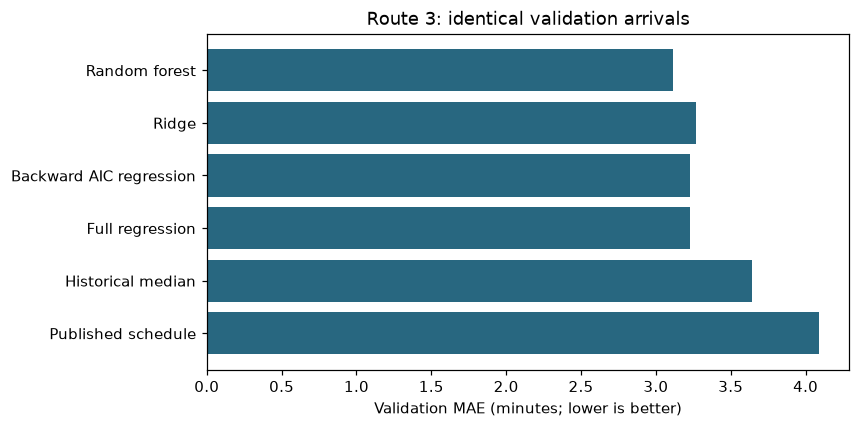

In [13]:
validation_predictions = validation[["source_row", "service_date", "bus_id", "stop_id", "direction_id", "scheduled_arrival", "actual_arrival", TARGET]].copy()
score_rows = []
for name in METHODS:
    pred, settings = predict_procedure(name, train, validation)
    validation_predictions[name] = pred
    score_rows.append({"method": name, "chosen_by_training_folds": name == chosen_method, "settings": settings, "MAE_minutes": mean_absolute_error(validation[TARGET], pred), "RMSE_minutes": np.sqrt(mean_squared_error(validation[TARGET], pred)), "validation_R2": r2_score(validation[TARGET], pred)})
validation_results = pd.DataFrame(score_rows)
display(validation_results.round(3))
validation_predictions["predicted_arrival"] = validation_predictions.scheduled_arrival + pd.to_timedelta(validation_predictions[chosen_method], unit="min")
validation_predictions["absolute_error_minutes"] = (validation_predictions[chosen_method] - validation[TARGET]).abs()
print("Chosen approach:", chosen_method)
display(validation_predictions[["source_row", "scheduled_arrival", "actual_arrival", "predicted_arrival", "absolute_error_minutes"]].head(8))
for group in ["service_date", "direction_id", "bus_id"]:
    print("Errors by", group)
    display(validation_predictions.groupby(group).absolute_error_minutes.agg(["size", "mean"]).rename(columns={"mean": "MAE_minutes"}))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(validation_results.method, validation_results.MAE_minutes, color="#286780")
ax.set(xlabel="Validation MAE (minutes; lower is better)", title="Route 3: identical validation arrivals")
fig.tight_layout()
plt.show()

## Visual guide - demonstrate the results

The earlier bar chart compares **average** error across methods. The next figures show individual misses, stability across dates, and what the fitted model learns about hour.

These plots use the same training/validation split and chosen model. They do not tune it or access final-test outcomes.

### Graph 1. Actual versus predicted arrival delay

Each point is one validation arrival. A perfect prediction lies on the dashed diagonal. Compare using the schedule alone (zero predicted delay) with our training-fold-chosen method. Below the diagonal means we underestimated delay; above means we overestimated it. The axes show minutes relative to schedule, so a predicted delay of 3 minutes means adding 3 minutes to the published arrival time.

**Discuss:** which large delays remain difficult? Improving an average does not mean every arrival improves.

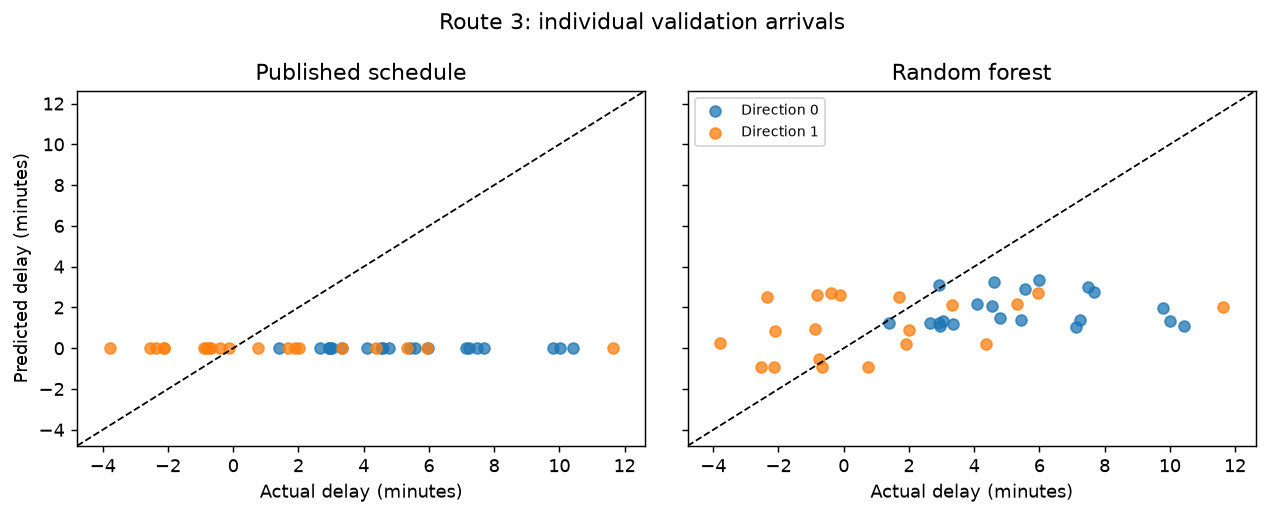

In [14]:
actual_delay = validation_predictions[TARGET].to_numpy()
model_delay = validation_predictions[chosen_method].to_numpy()
limits = [min(actual_delay.min(), model_delay.min(), 0) - 1,
          max(actual_delay.max(), model_delay.max(), 0) + 1]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ["Published schedule", chosen_method]):
    predicted = validation_predictions[name].to_numpy()
    for direction in sorted(validation_predictions.direction_id.unique()):
        mask = validation_predictions.direction_id.eq(direction)
        ax.scatter(actual_delay[mask], predicted[mask], alpha=0.75, label=f"Direction {direction}")
    ax.plot(limits, limits, "k--", linewidth=1)
    ax.set(xlim=limits, ylim=limits, xlabel="Actual delay (minutes)", title=name)
axes[0].set_ylabel("Predicted delay (minutes)")
axes[1].legend(fontsize=8)
fig.suptitle("Route 3: individual validation arrivals", fontsize=12)
fig.tight_layout()
plt.show()

### Graph 2. Error by validation date

Each group of bars describes one whole date. Lower bars mean better prediction. Counts above each group show how many arrivals contribute; some dates have fewer usable matches.

**Discuss:** does the model improve on the schedule every day, or is its overall improvement driven by one date? This is descriptive error analysis, not a reason to remove a difficult date.

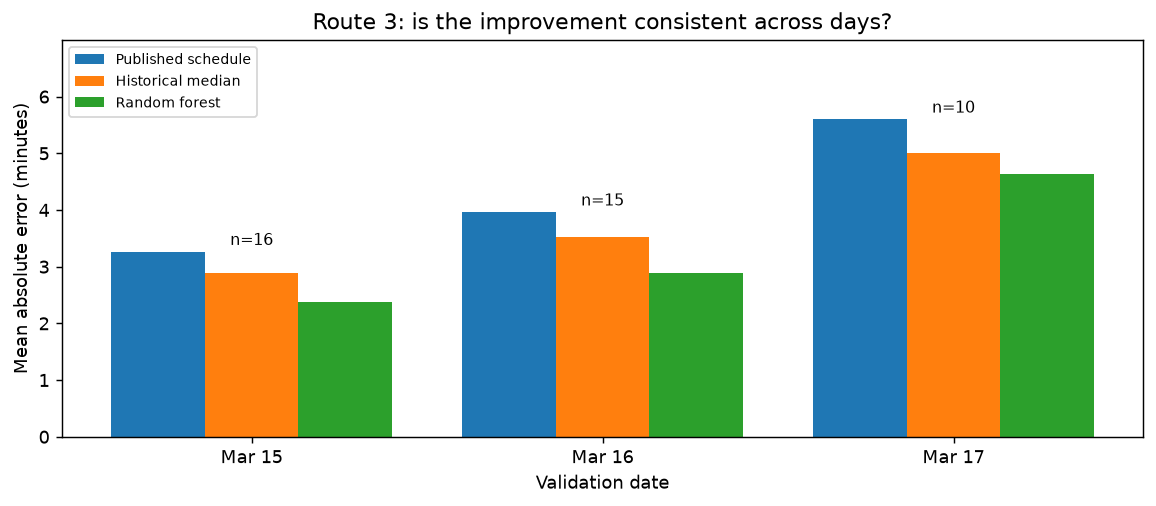

,arrivals,Published schedule,Historical median,Random forest
service_date,,,,
2023-03-15,16,3.264,2.895,2.380
2023-03-16,15,3.960,3.532,2.893
2023-03-17,10,5.598,5.008,4.629


In [15]:
comparison_methods = list(dict.fromkeys(["Published schedule", "Historical median", chosen_method]))
daily = validation_predictions.groupby("service_date").size().to_frame("arrivals")
for name in comparison_methods:
    errors = (validation_predictions[name] - validation_predictions[TARGET]).abs()
    daily[name] = errors.groupby(validation_predictions.service_date).mean()
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(daily))
width = 0.8 / len(comparison_methods)
for j, name in enumerate(comparison_methods):
    ax.bar(x + (j - (len(comparison_methods)-1)/2)*width, daily[name], width, label=name)
for j, (_, row) in enumerate(daily.iterrows()):
    ax.text(j, row[comparison_methods].max()+0.12, f"n={int(row.arrivals)}", ha="center", fontsize=9)
ax.set_xticks(x, daily.index.strftime("%b %d"))
ax.set(xlabel="Validation date", ylabel="Mean absolute error (minutes)", title="Route 3: is the improvement consistent across days?")
ax.set_ylim(0, daily[comparison_methods].to_numpy().max()*1.25)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
display(daily.round(3))

### Graph 3. What happens to predictions across the day?

Hold weekday fixed at the most common training weekday and plot each direction's predictions across its **observed training hours for that weekday**. Model fitting still uses all training dates; the plotted inputs vary hour while keeping weekday and direction fixed. We do not create combinations outside the observed support.

The dashed horizontal line is the historical median prediction. Separate direction curves also represent different Walmart stop locations. This is a demonstration of the model's learned associations, **not evidence that changing the hour causes a delay**, and not an evaluation on unseen data. No recent actual arrival or passenger counts enter these inputs.

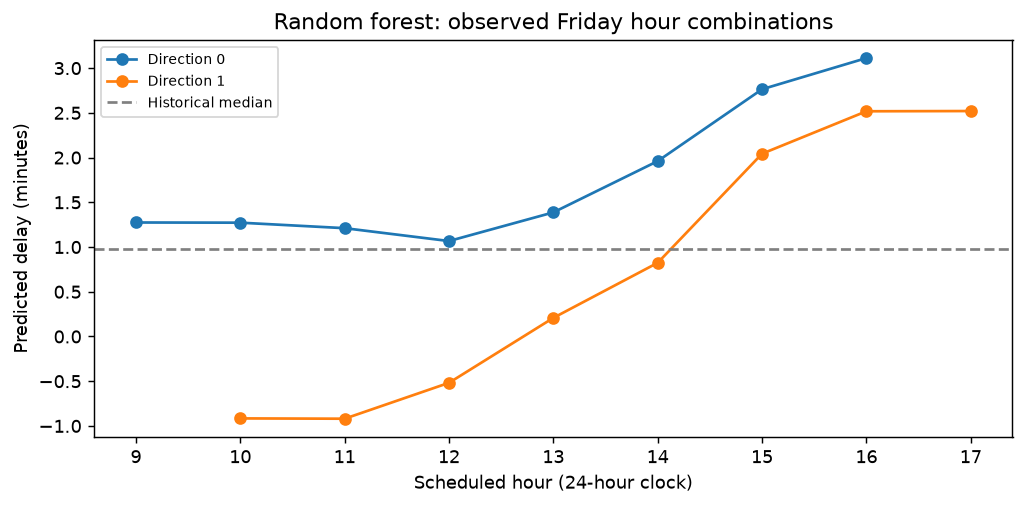

,direction_id,scheduled_hour,weekday,predicted_delay_minutes
0,0,9,Friday,1.274
1,0,10,Friday,1.272
2,0,11,Friday,1.211
3,0,12,Friday,1.067
4,0,13,Friday,1.387
5,0,14,Friday,1.960
6,0,15,Friday,2.764
7,0,16,Friday,3.112
8,1,10,Friday,-0.916
9,1,11,Friday,-0.919


In [16]:
demo_weekday = train.weekday.mode().iloc[0]
demo_inputs = (train.loc[train.weekday.eq(demo_weekday), GROUPS]
               .drop_duplicates().sort_values(["direction_id", "scheduled_hour"]))
demo_prediction, demo_settings = predict_procedure(chosen_method, train, demo_inputs)
demo = demo_inputs.copy()
demo["predicted_delay_minutes"] = demo_prediction
fig, ax = plt.subplots(figsize=(8, 4))
for direction, part in demo.groupby("direction_id"):
    ax.plot(part.scheduled_hour, part.predicted_delay_minutes, marker="o", label=f"Direction {direction}")
ax.axhline(train[TARGET].median(), color="gray", linestyle="--", label="Historical median")
ax.set(xlabel="Scheduled hour (24-hour clock)", ylabel="Predicted delay (minutes)",
       title=f"{chosen_method}: observed {demo_weekday} hour combinations")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
display(demo.reset_index(drop=True).round(3))

### How to present these figures

1. Begin with the average-error bar chart: which approach has the smallest average miss?
2. Show the scatter plots: averages hide large individual misses.
3. Show the date bars: ask whether the benefit is stable across days.
4. Show the hour curves: explain what the model predicts when known schedule inputs change.

Always mention that matches are provisional and only the retained Walmart timepoints are represented. The optional PNG files in the download package can be used in slides.

## 8. Results explained

### How much data did we model?
The original workbook has **8,642 stop visits**, **17 observed dates**, and **3 buses**. We retain **196 intermediate development arrivals**: **155 training** and **41 validation** observations. These cover NE Walmart Supercenter's two directional stops, 1235 and 1234, not every Route 3 stop. **477 other timepoint records** remain held for review; untimed stops are outside this target population.

### Are the targets verified?
No. Matches have consistent patterns and other-timepoint support, but remain inferred assignments rather than independently confirmed GTFS trip IDs. A 20-minute target matching window restricts inclusion and may omit severe delays or ambiguous visits. Our scores describe retained timepoints, not route-wide performance or a deployable live system.

### What did the regression tell us?
The full regression has training R² **0.333**, adjusted R² **0.306**, classical F-statistic **12.34**, ordinary F-test p-value **3.09e-11**, AIC **689.94**, and BIC **711.24**. These describe training association under assumptions; repeated observations and only ten days limit significance claims. Read the clustered uncertainty table too.

Backward AIC retains **direction_id, scheduled_hour, weekday**. Its AIC is **689.94**, BIC **711.24**. Route 3 is allowed to choose differently from Route 7.

### Which procedure won?
Training-date folds select **Random forest**, with MAE **2.056 minutes**. On the later validation dates its MAE is **3.116 minutes**. The lowest validation MAE belongs to **Random forest** at **3.116 minutes**. Report any disagreement; do not silently reselect on validation or claim a universal winner from three dates.

### Are predictions better than the timetable?
The published timetable's validation MAE is **4.088 minutes**. The median scores **3.643 minutes**, a **10.9% reduction** (a negative reduction means worse). The training-fold-chosen method scores **3.116 minutes**, a **23.8% reduction**. These percentages are reductions in average absolute error, not classification accuracy. We compare with published times, not Navigator's live estimate.

### Did selection, regularization, or a forest help?
Validation MAEs are full regression **3.228**, backward selection **3.228**, ridge **3.265**, and forest **3.116 minutes**. Compare these with the median **3.643** as well as the schedule **4.088**. Better training AIC does not guarantee lower future-date MAE.

### Can we compare Route 3 and Route 7 directly?
The development calendar boundaries match, but modeled stops, sample counts, and selection patterns differ. Report each route's error and improvement over its own baseline. A smaller raw MAE is not proof that a route is inherently easier or a model transfers universally.

### Practical synthesis

- **Random forest is the current training-fold choice, and it also wins this validation comparison.** Its mean absolute miss is about **3 minutes 7 seconds**, compared with **4 minutes 5 seconds** for the timetable: about **58 seconds less error per arrival on average**.
- **This is improvement, not precise arrival prediction.** Forest MAE rises from about 2.06 minutes on training-date folds to 3.12 on validation, and its validation R² is still negative (about -0.065). Squared error is worse than an oracle that knows the validation mean; that mean is not available in advance and is not our operational baseline. Later dates are harder for these models.
- **Backward selection made no final removal.** All three groups remain on the complete training set, so its validation predictions equal full regression. The fold scores differ because some earlier training portions select differently.
- **Ridge did not improve this comparison.** Its training-only tuned alpha is 10 when refitted on all training dates. Validation MAE of 3.27 minutes is slightly worse than full regression's 3.23 minutes. Regularization is worth testing, not assumed beneficial.
- **Route-specific learning matters.** Route 7 removed weekday and favored the median on validation; Route 3 retains weekday and favors the forest in this sample. This supports repeating the procedure per route rather than copying a fitted model.
- **Do not claim system-wide generalization yet.** Matching remains provisional; a time-window inclusion rule and only three validation dates limit interpretation. The held-out final dates have not been evaluated.


### Coefficients in plain language

- Per hour later in the schedule, estimated delay changes by **+0.495 minutes**, holding other inputs fixed (ordinary 95% interval +0.343 to +0.648).
- For `direction_id_1` versus its reference category, estimated delay changes by **-1.767 minutes**, holding other inputs fixed (ordinary 95% interval -2.480 to -1.054).
- For `weekday_Monday` versus its reference category, estimated delay changes by **+1.649 minutes**, holding other inputs fixed (ordinary 95% interval +0.548 to +2.749).
- For `weekday_Thursday` versus its reference category, estimated delay changes by **+0.663 minutes**, holding other inputs fixed (ordinary 95% interval -0.438 to +1.764).
- For `weekday_Tuesday` versus its reference category, estimated delay changes by **+2.014 minutes**, holding other inputs fixed (ordinary 95% interval +0.922 to +3.105).
- For `weekday_Wednesday` versus its reference category, estimated delay changes by **+0.266 minutes**, holding other inputs fixed (ordinary 95% interval -0.817 to +1.348).

Reference direction is 0; reference weekday is the alphabetically first observed training weekday. Direction also identifies the two different modeled stops, so this contrast combines direction and location. Effects are associations, not causal. The hour-zero intercept is outside observed service hours.

## 9. Research questions - with answers

**Why are most raw records not training rows?**  
They may be untimed stops, reserved dates, terminal visits, or records needing linkage review. An absent schedule-delay label does not mean a raw row is invalid.

**Why pool buses?**  
Samples per bus are small and bus identity is entangled with operating dates. Pool observations, split whole dates, and inspect errors by bus/date afterward.

**Why keep unusually large delays?**  
An extreme value can be genuine. Training-only IQR flags identify review candidates; no rows are deleted just to improve prediction scores.

**Why not include stop ID and direction together?**  
Each modeled Walmart stop belongs to one direction in this sample, so they encode the same division. Check this again on each new route.

**How is ridge tuning protected against look-ahead?**  
Only inner chronological folds within an outer training portion select alpha. The outer dates evaluate the full tuning procedure. Final validation dates do not choose alpha.

**What else could leak future information?**  
Target-stop passenger counts, later observations used as predictors, fitting encoders/selection on evaluation rows, and choosing rules using final-test outcomes. Retrospective journey evidence supports provisional labels only; it is never a predictor.

**Do p-values decide the best predictor set?**  
No. Consider effect size, dependence, redundancy, prediction-time availability, complexity, and later-date error. Selection also makes naive post-selection significance claims unreliable.

**What transfers to Routes 11 and 711?**  
The procedure and reporting format, not fitted coefficients or hard-coded timed-stop IDs. Check each route's patterns, calendar, terminal semantics, samples, and splits before fitting.

**Can we generalize to all RTS service now?**  
No. This adds one route's retained timepoints. Separate-versus-pooled and leave-one-route-out experiments can follow after route-level audits, with chronology preserved. Route 711's weekend-heavy sample needs special care.

**What remains before a final claim?**  
Resolve linkage concerns, freeze the complete preparation/feature/selection rules, refit on approved development data, and score reserved final dates once.

**Where did the inputs come from?**  
Richard Borzi / University of Florida, data supplied by Gainesville RTS, CC BY 4.0: [Route 3 record](https://zenodo.org/records/10034688). Historical [Spring 2023 GTFS](https://www.ftis.org/PostFileDownload.aspx?id=602A0). Keep source attribution when sharing derived work.

## Optional - save outputs for later comparisons

Uncomment if needed. These are new outputs, not required inputs. Retain split and linkage status in research records but never use them as predictors.

In [17]:
# cleaned.to_csv("Route3_Development.csv", index=False)
# held.to_csv("Route3_Held_For_Review.csv", index=False)
# validation_results.to_csv("Route3_Validation_Results.csv", index=False)
# fold_results.to_csv("Route3_Training_Date_Folds.csv", index=False)